<a href="https://colab.research.google.com/github/ancestor9/Scikit-learn-model-selection-evaluation/blob/main/practices/end2end_ml.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
path = "https://raw.githubusercontent.com/wesm/pydata-book/3rd-edition/datasets/titanic/train.csv"
df = pd.read_csv(path)
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [2]:
def summarize_df_lite(df: pd.DataFrame, top_n: int = 7) -> pd.DataFrame:
    rows = []
    n = len(df)
    for col in df.columns:
        s = df[col]
        top = s.value_counts(dropna=True).head(top_n)
        missing = int(s.isna().sum())
        rows.append({
            "col": col,
            "dtype": str(s.dtype),
            "missing": missing,
            "missing_pct": round(missing / n * 100, 2) if n else 0.0,  # 결측치 비율(%)
            "unique": int(s.nunique(dropna=True)),
            "top_values": ", ".join(f"{v} ({c})" for v, c in top.items()),
        })
    return pd.DataFrame(rows)

In [3]:
# @title **1. 데이터 요약**
summarize_df_lite(df)

,col,dtype,missing,missing_pct,unique,top_values
0,PassengerId,int64,0,0.00,891,"1 (1), 2 (1), 3 (1), 4 (1), 5 (1), 6 (1), 7 (1)"
1,Survived,int64,0,0.00,2,"0 (549), 1 (342)"
2,Pclass,int64,0,0.00,3,"3 (491), 1 (216), 2 (184)"
3,Name,object,0,0.00,891,"Braund, Mr. Owen Harris (1), Cumings, Mrs. Joh..."
4,Sex,object,0,0.00,2,"male (577), female (314)"
5,Age,float64,177,19.87,88,"24.0 (30), 22.0 (27), 18.0 (26), 28.0 (25), 30..."
6,SibSp,int64,0,0.00,7,"0 (608), 1 (209), 2 (28), 4 (18), 3 (16), 8 (7..."
7,Parch,int64,0,0.00,7,"0 (678), 1 (118), 2 (80), 5 (5), 3 (5), 4 (4),..."
8,Ticket,object,0,0.00,681,"347082 (7), 1601 (7), CA. 2343 (7), 3101295 (6..."
9,Fare,float64,0,0.00,248,"8.05 (43), 13.0 (42), 7.8958 (38), 7.75 (34), ..."


In [4]:
# @title **2. Feature와 Target의 관계**
def conditional_entropy(x,y):
    # entropy of x given y
    y_counter = Counter(y)
    xy_counter = Counter(list(zip(x,y)))
    total_occurrences = sum(y_counter.values())
    entropy = 0
    for xy in xy_counter.keys():
        p_xy = xy_counter[xy] / total_occurrences
        p_y = y_counter[xy[1]] / total_occurrences
        entropy += p_xy * math.log(p_y/p_xy)
    return entropy

def theil_u(x,y):
    s_xy = conditional_entropy(x,y)
    x_counter = Counter(x)
    total_occurrences = sum(x_counter.values())
    p_x = list(map(lambda n: n/total_occurrences, x_counter.values()))
    s_x = ss.entropy(p_x)
    if s_x == 0:
        return 1
    else:
        return (s_x - s_xy) / s_x

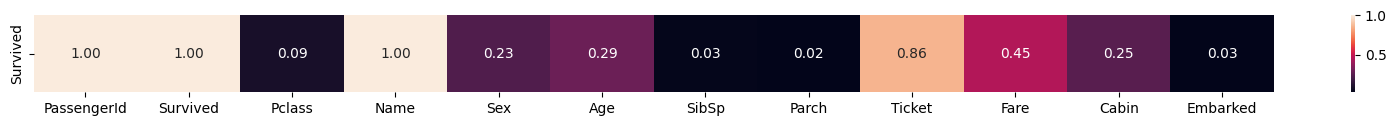

In [5]:
import math
import numpy as np
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as ss

theilu = pd.DataFrame(index=['Survived'],columns=df.columns)
columns = df.columns
for j in range(0,len(columns)):
    u = theil_u(df['Survived'].tolist(),df[columns[j]].tolist())
    theilu.loc[:,columns[j]] = u
theilu.fillna(value=np.nan,inplace=True)

# 데이터프레임의 타입을 float으로 명시적 변환하여 오류를 해결합니다.
theilu = theilu.astype(float)

plt.figure(figsize=(20,1))
sns.heatmap(theilu,annot=True,fmt='.2f')
plt.show()

In [8]:
# @title **3. 불필요한 데이터 제거**
df.drop(columns=['PassengerId','Name','Ticket','Cabin'],inplace=True)
df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


In [10]:
# @title **4. 훈련과 검증 데이터 분리**

from sklearn.model_selection import train_test_split

target = "Survived"
X = df.drop(columns=[target]); y = df[target]
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.2,
                                                    stratify=y,
                                                    random_state=42
                                                    )

In [18]:
# @title **6. 데이터전처리/모델 파이프라인**
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier

num_cols = ["Age", "SibSp", "Parch", "Fare"]
cat_cols = ["Pclass", "Sex", "Embarked"]

num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

# ColumnTransformer
preprocessor = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols),
])

# 전체 파이프라인 (전처리 + 모델)
pipe = Pipeline([
    ("prep", preprocessor),
    ("model", RandomForestClassifier(random_state=42)),
])

pipe

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Age', 'SibSp', 'Parch',
                                                   'Fare']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Pclass', 'Sex',
                                                   'Embarked'])])),
                ('model', RandomForestClassifier(random_state=42))])

In [15]:
pipe[0]

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['Age', 'SibSp', 'Parch', 'Fare']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['Pclass', 'Sex', 'Embarked'])])

In [16]:
pipe[1]

RandomForestClassifier(random_state=42)

In [21]:
# @title **7. 교차검증**
from sklearn.model_selection import StratifiedKFold, cross_val_score
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(pipe,
                         X_train, y_train,
                         cv=cv,
                         scoring="accuracy")
print(f'교차검증: {scores}')
print(f"CV accuracy: {scores.mean():.4f} ± {scores.std():.4f}")

교차검증: [0.81818182 0.78321678 0.80985915 0.76760563 0.80985915]
CV accuracy: 0.7977 ± 0.0191


In [23]:
# @title **8. 교차검증 및 하이퍼파라미터 튜닝**

from sklearn.model_selection import RandomizedSearchCV
param_dist = {
    "model__n_estimators": [100, 200, 300, 500],
    "model__max_depth": [None, 3, 5, 7, 10],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", "log2", None],
    "prep__num__imputer__strategy": ["mean", "median"],  # 전처리 파라미터도 탐색 가능
}

search = RandomizedSearchCV(
    pipe,
    param_distributions=param_dist,
    n_iter=30,
    cv=cv,
    scoring="accuracy",
    random_state=42,
    n_jobs=-1,
    verbose=2,
)
search.fit(X_train, y_train)

print("Best params:", search.best_params_)
print(f"Best CV score: {search.best_score_:.4f}")

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best params: {'prep__num__imputer__strategy': 'median', 'model__n_estimators': 300, 'model__min_samples_split': 10, 'model__min_samples_leaf': 1, 'model__max_features': None, 'model__max_depth': 10}
Best CV score: 0.8300


In [24]:
# @title **9. 테스트셋 최종 평가**
best_model = search.best_estimator_
print(f"Test accuracy: {best_model.score(X_test, y_test):.4f}")

Test accuracy: 0.7989


In [27]:
pd.DataFrame(search.cv_results_).sort_values(by="rank_test_score").iloc[:, 4:].head()

,param_prep__num__imputer__strategy,param_model__n_estimators,param_model__min_samples_split,param_model__min_samples_leaf,param_model__max_features,param_model__max_depth,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
28,median,300,10,1,None,10,"{'prep__num__imputer__strategy': 'median', 'mo...",0.853147,0.818182,0.845070,0.802817,0.830986,0.830040,0.018124,1
15,mean,100,10,1,sqrt,5,"{'prep__num__imputer__strategy': 'mean', 'mode...",0.846154,0.825175,0.838028,0.809859,0.795775,0.822998,0.018333,2
10,mean,100,10,2,None,10,"{'prep__num__imputer__strategy': 'mean', 'mode...",0.811189,0.811189,0.859155,0.802817,0.823944,0.821659,0.019927,3
1,mean,300,10,2,log2,5,"{'prep__num__imputer__strategy': 'mean', 'mode...",0.853147,0.811189,0.852113,0.795775,0.795775,0.821600,0.025956,4
8,median,500,5,4,None,10,"{'prep__num__imputer__strategy': 'median', 'mo...",0.818182,0.804196,0.859155,0.802817,0.816901,0.820250,0.020449,5


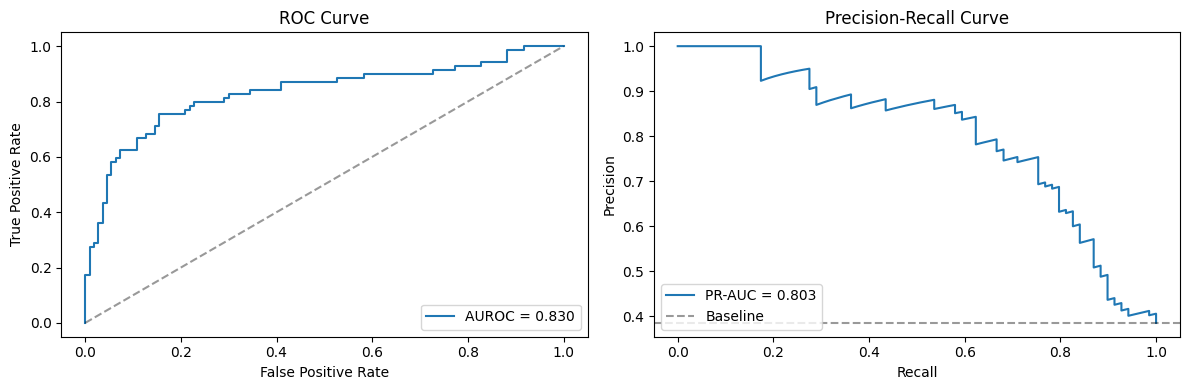

              precision    recall  f1-score   support

           0     0.8033    0.8909    0.8448       110
           1     0.7895    0.6522    0.7143        69

    accuracy                         0.7989       179
   macro avg     0.7964    0.7715    0.7796       179
weighted avg     0.7980    0.7989    0.7945       179



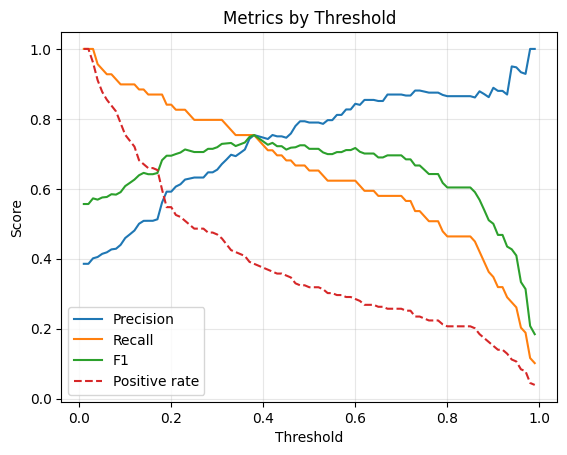

In [31]:
# @title **9. 시각화(테스트셋 최종 평가)**
from sklearn.metrics import (
    roc_curve, roc_auc_score,
    precision_recall_curve, average_precision_score,
    classification_report,
    precision_score, recall_score, f1_score,
)

# 예측 확률 (양성 클래스)
y_proba = best_model.predict_proba(X_test)[:, 1]

# 1) ROC / PR 곡선
fpr, tpr, _ = roc_curve(y_test, y_proba)
prec, rec, _ = precision_recall_curve(y_test, y_proba)
auroc = roc_auc_score(y_test, y_proba)
prauc = average_precision_score(y_test, y_proba)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(fpr, tpr, label=f"AUROC = {auroc:.3f}")
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[0].set(xlabel="False Positive Rate", ylabel="True Positive Rate", title="ROC Curve")
axes[0].legend(loc="lower right")

axes[1].plot(rec, prec, label=f"PR-AUC = {prauc:.3f}")
axes[1].axhline(y_test.mean(), color="k", linestyle="--", alpha=0.4, label="Baseline")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision-Recall Curve")
axes[1].legend(loc="lower left")

plt.tight_layout()
plt.show()

# 2) Classification report (threshold = 0.5)
y_pred = (y_proba >= 0.5).astype(int)
print(classification_report(y_test, y_pred, digits=4))

# 3) Threshold별 지표
thresholds = np.linspace(0.01, 0.99, 99)
rows = []
for t in thresholds:
    pred = (y_proba >= t).astype(int)
    rows.append((
        precision_score(y_test, pred, zero_division=0),
        recall_score(y_test, pred, zero_division=0),
        f1_score(y_test, pred, zero_division=0),
        pred.mean(),  # 양성으로 판정한 비율
    ))
p, r, f, pos_rate = zip(*rows)

plt.figure()
plt.plot(thresholds, p, label="Precision")
plt.plot(thresholds, r, label="Recall")
plt.plot(thresholds, f, label="F1")
plt.plot(thresholds, pos_rate, label="Positive rate", linestyle="--")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Metrics by Threshold")
plt.legend()
plt.grid(alpha=0.3)
plt.show()